# 第 04 章　连接器：把"视觉特征"翻译成"语言 token"

视觉编码器输出 **1024 个 768 维**向量，语言模型（SmolLM2-135M）的词向量是 **576 维**。连接器解决两个问题：

| 问题 | 做法 | 形状变化 |
|---|---|---|
| token 太多，语言模型算不过来 | **Pixel Shuffle**：每 4×4 个相邻 patch 拼成 1 个 token | `[1, 1024, 768] → [1, 64, 12288]` |
| 维度不同，"语言"不通 | **线性投影**：一个 12288→576 的矩阵 | `[1, 64, 12288] → [1, 64, 576]` |

整个连接器只有**一个线性层**（约 708 万参数），却是视觉和语言之间唯一的桥梁。

In [1]:
import sys, pathlib  # 路径工具
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "vlmlab").exists())  # 找项目根目录
sys.path.insert(0, str(ROOT))  # 加入导入路径

import numpy as np  # 数组
import torch  # PyTorch
import torch.nn.functional as F  # 函数式接口
import matplotlib.pyplot as plt  # 绘图
from vlmlab import *  # 共享工具

setup_matplotlib()  # 中文字体
device = get_device()  # mps
processor, model = load_smolvlm(device)  # 加载模型
connector = model.model.connector  # 连接器
print(connector)  # 打印结构
print("scale_factor =", connector.scale_factor)  # 4
inputs = build_inputs(processor, load_photo(), split=False)  # 预处理（第 02 章）
pv = inputs["pixel_values"][:, 0]  # [1,3,512,512]
img512 = (pv[0].cpu() * 0.5 + 0.5).clamp(0, 1)  # 用于显示
with torch.no_grad():  # 不要梯度
    vis = model.model.vision_model(pixel_values=pv).last_hidden_state  # 第 03 章的输出 [1,1024,768]
print("视觉编码器输出:", tuple(vis.shape))  # 打印

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

Idefics3Connector(
  (modality_projection): Idefics3SimpleMLP(
    (proj): Linear(in_features=12288, out_features=576, bias=False)
  )
)
scale_factor = 4
视觉编码器输出: (1, 1024, 768)


## 1. Pixel Shuffle 小例子
用一个 8×8 的网格（64 个 patch，每个只有 1 维，值就是编号）演示 `scale=4` 的 pixel shuffle。

结果：64 个 patch → **4 个 token**，每个 token 是 16 维，正好是一个 4×4 区域里 16 个 patch 的值**拼接**起来。

In [2]:
toy = torch.arange(64).view(1, 64, 1)  # [batch=1, 64 个 patch, 1 维]，值为编号
out = connector.pixel_shuffle(toy, 4)  # 官方实现
print("输入 8×8 网格:\n", toy.view(8, 8))  # 打印原网格
print("输出", tuple(out.shape), "：每行是一个新 token 拼进来的 16 个 patch 编号")  # 打印
print(out[0])  # 第 0 个 token 包含左上 4×4 块：0,1,2,3,8,9,10,11,...

输入 8×8 网格:
 tensor([[ 0,  1,  2,  3,  4,  5,  6,  7],
        [ 8,  9, 10, 11, 12, 13, 14, 15],
        [16, 17, 18, 19, 20, 21, 22, 23],
        [24, 25, 26, 27, 28, 29, 30, 31],
        [32, 33, 34, 35, 36, 37, 38, 39],
        [40, 41, 42, 43, 44, 45, 46, 47],
        [48, 49, 50, 51, 52, 53, 54, 55],
        [56, 57, 58, 59, 60, 61, 62, 63]])
输出 (1, 4, 16) ：每行是一个新 token 拼进来的 16 个 patch 编号
tensor([[ 0,  1,  2,  3,  8,  9, 10, 11, 16, 17, 18, 19, 24, 25, 26, 27],
        [ 4,  5,  6,  7, 12, 13, 14, 15, 20, 21, 22, 23, 28, 29, 30, 31],
        [32, 33, 34, 35, 40, 41, 42, 43, 48, 49, 50, 51, 56, 57, 58, 59],
        [36, 37, 38, 39, 44, 45, 46, 47, 52, 53, 54, 55, 60, 61, 62, 63]])


官方实现用了两次 `view + permute`，不太好读。下面用**一次 reshape + 一次 permute** 写出等价版本，第 00 章切照片时用的就是同一招：
```
[B, 32×32, D] → [B, 8, 4, 8, 4, D]    行 = 第几个大块 × 块内第几行；列同理
              → permute → [B, 8, 8, 4, 4, D]
              → reshape → [B, 64, 16·D]
```

In [3]:
def my_pixel_shuffle(x, s=4):  # 手写 pixel shuffle
    B, N, D = x.shape  # [B, 1024, 768]
    g = int(N ** 0.5)  # 每边 32 个 patch
    x = x.view(B, g // s, s, g // s, s, D)  # [B, 8, 4, 8, 4, D]
    x = x.permute(0, 1, 3, 2, 4, 5)  # [B, 8(大块行), 8(大块列), 4(块内行), 4(块内列), D]
    return x.reshape(B, (g // s) ** 2, s * s * D)  # [B, 64, 16·D]

print("小例子一致吗？", torch.equal(my_pixel_shuffle(toy), out))  # True
shuffled = my_pixel_shuffle(vis)  # 真实数据：[1, 64, 12288]
check_close("Pixel Shuffle（真实特征）", shuffled, connector.pixel_shuffle(vis, 4), atol=0)  # 只是搬运数据，必须完全相等
print("pixel shuffle 后:", tuple(shuffled.shape))  # 打印

小例子一致吗？ True
✅ Pixel Shuffle（真实特征）: 形状 (1, 64, 12288)，最大误差 0.00e+00（容差 0e+00）
pixel shuffle 后: (1, 64, 12288)


### 画出来：每个新 token 覆盖原图哪块区域
32×32 的 patch 网格被分成 8×8 个大块，每块 4×4 个 patch，对应原图 64×64 像素。**一个语言 token = 原图 64×64 像素的区域。**

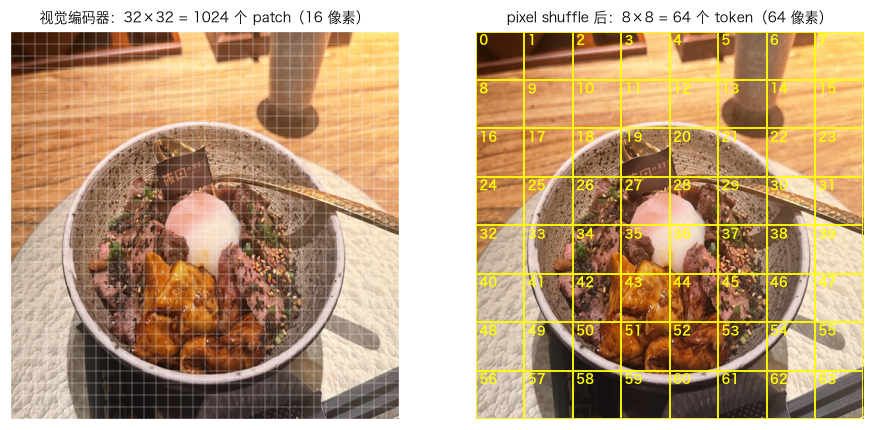

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))  # 两个子图
draw_patch_grid(img512, 16, ax=axes[0], lw=0.2, title="视觉编码器：32×32 = 1024 个 patch（16 像素）")  # 细网格
draw_patch_grid(img512, 64, ax=axes[1], lw=1.2, color="yellow", title="pixel shuffle 后：8×8 = 64 个 token（64 像素）")  # 粗网格
for t in range(64):  # 标号
    axes[1].text((t % 8) * 64 + 4, (t // 8) * 64 + 16, str(t), color="yellow", fontsize=8, weight="bold")  # 写 token 编号
plt.show()  # 显示

**为什么不直接平均池化？** 平均会把 16 个 patch 混成一个 768 维向量，丢掉块内的空间细节。Pixel shuffle 把 16 个向量**原样拼接**（16×768 = 12288 维），不丢任何信息，只是把"空间分辨率"换成了"通道深度"。至于保留什么、丢掉什么，交给后面的线性层去学。

In [5]:
dims = [("视觉输出", vis), ("pixel shuffle", shuffled)]  # 两个阶段
for name, t in dims:  # 打印数据量
    print(f"{name:14s} 形状 {str(tuple(t.shape)):18s} 数字总数 {t.numel():>9,d}")  # 二者相同，只是重新排列

视觉输出           形状 (1, 1024, 768)     数字总数   786,432
pixel shuffle  形状 (1, 64, 12288)     数字总数   786,432


## 2. 线性投影：12288 → 576
`nn.Linear(12288, 576, bias=False)`，就是一次矩阵乘法 $Y = X W^\top$。这一步把信息压缩约 21 倍，并映射到语言模型的词向量空间。

In [6]:
proj = connector.modality_projection.proj  # 线性层
print("投影矩阵:", tuple(proj.weight.shape), f"= {proj.weight.numel()/1e6:.2f}M 参数")  # [576, 12288]
with torch.no_grad():  # 不要梯度
    img_tokens = shuffled @ proj.weight.T  # 手写：[1,64,12288] @ [12288,576] → [1,64,576]
    official = connector(vis)  # 官方连接器（pixel shuffle + 投影）
check_close("连接器输出", img_tokens, official, atol=1e-4)  # 对比
print(f"压缩比：{shuffled.numel()} → {img_tokens.numel()}，约 {shuffled.numel()/img_tokens.numel():.0f} 倍")  # 打印

投影矩阵: (576, 12288) = 7.08M 参数
✅ 连接器输出: 形状 (1, 64, 576)，最大误差 0.00e+00（容差 1e-04）
压缩比：786432 → 36864，约 21 倍


### 投影矩阵在"看"块内哪个位置？
12288 维 = 16 个位置 × 768 维。把投影矩阵按位置拆开，计算每个块内位置的权重大小，可以看出线性层对 4×4 块内哪些位置更"重视"。

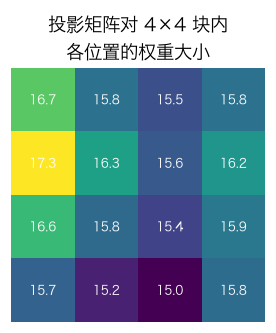

In [7]:
Wp = proj.weight.detach().cpu().view(576, 16, 768)  # [输出维, 块内位置, 视觉维]
pos_importance = Wp.norm(dim=(0, 2)).view(4, 4)  # 每个块内位置的权重范数
plt.figure(figsize=(3.2, 3))  # 画布
plt.imshow(pos_importance, cmap="viridis")  # 4×4 热力图
for r in range(4):  # 标数值
    for c in range(4):  # 每格
        plt.text(c, r, f"{pos_importance[r, c]:.1f}", ha="center", va="center", color="white", fontsize=8)  # 写数
plt.title("投影矩阵对 4×4 块内\n各位置的权重大小")  # 标题
plt.axis("off")  # 去坐标轴
plt.show()  # 显示

## 3. 图片现在变成了什么？
现在只剩 **8×8 = 64 个 576 维向量**。用 PCA 着色，并与第 03 章 32×32 的结果对比。

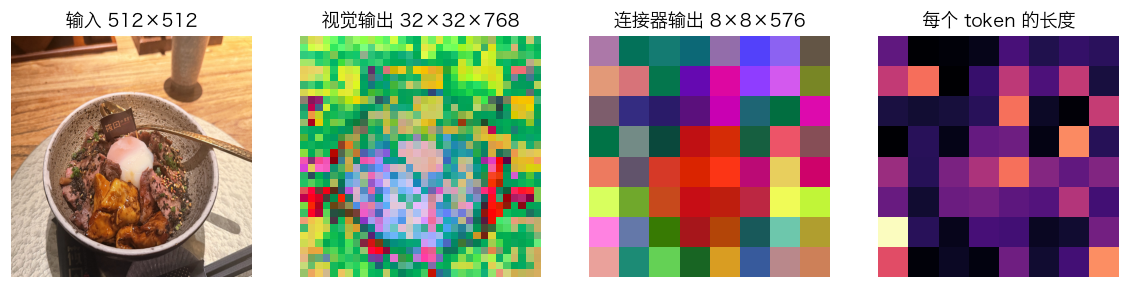

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))  # 四个子图
axes[0].imshow(img512.permute(1, 2, 0))  # 原图
axes[0].set_title("输入 512×512")  # 标题
axes[1].imshow(pca_rgb(vis[0]))  # 视觉输出
axes[1].set_title("视觉输出 32×32×768")  # 标题
axes[2].imshow(pca_rgb(img_tokens[0]), interpolation="nearest")  # 连接器输出
axes[2].set_title("连接器输出 8×8×576")  # 标题
axes[3].imshow(img_tokens[0].norm(dim=-1).reshape(8, 8).cpu(), cmap="magma", interpolation="nearest")  # 范数
axes[3].set_title("每个 token 的长度")  # 标题
for ax in axes:  # 去坐标轴
    ax.axis("off")  # 关闭
plt.show()  # 显示

## 4. 图像 token 和"词"像吗？
连接器的输出会被**直接放进**语言模型的输入序列，和文字的词向量排在一起（第 05 章）。那么图像 token 和真正的词向量有多像？

1. 比较**长度**：图像 token 和词向量的范数分布
2. 找**最近的词**：对每个图像 token，在 49280 个词向量里找余弦相似度最高的

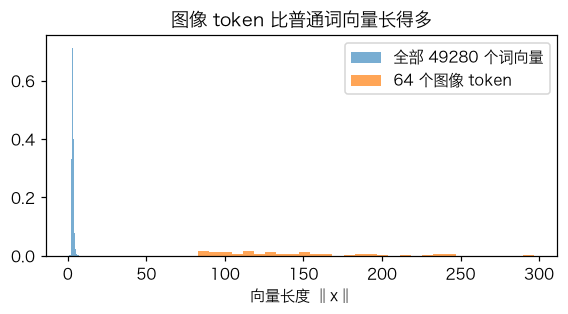

词向量长度中位数 3.06，图像 token 长度中位数 129.53


In [9]:
E = model.model.text_model.embed_tokens.weight.detach()  # 词向量表 [49280, 576]
tok = processor.tokenizer  # 分词器
img_t = img_tokens[0]  # [64, 576]
text_ids = tok("A bowl of rice with beef and egg on a wooden table.", return_tensors="pt").input_ids[0]  # 一句普通的话
text_t = E[text_ids.to(device)]  # 这句话的词向量
fig, ax = plt.subplots(figsize=(6, 2.6))  # 画布
ax.hist(E.norm(dim=-1).cpu().numpy(), bins=80, alpha=0.6, density=True, label="全部 49280 个词向量")  # 词向量长度分布
ax.hist(img_t.norm(dim=-1).cpu().numpy(), bins=30, alpha=0.7, density=True, label="64 个图像 token")  # 图像 token 长度分布
ax.set_xlabel("向量长度 ‖x‖")  # 横轴
ax.legend()  # 图例
ax.set_title("图像 token 比普通词向量长得多")  # 标题
plt.show()  # 显示
print(f"词向量长度中位数 {E.norm(dim=-1).median():.2f}，图像 token 长度中位数 {img_t.norm(dim=-1).median():.2f}")  # 打印

In [10]:
sim = F.normalize(img_t, dim=-1) @ F.normalize(E, dim=-1).T  # [64, 49280] 余弦相似度
best = sim.max(-1)  # 每个图像 token 最相似的词
words = [tok.decode([i]).strip() or repr(tok.decode([i])) for i in best.indices.tolist()]  # 解码成文字
print("每个图像 token 最接近的词（8×8 网格，对应图片位置）：\n")  # 标题
for r in range(8):  # 每行
    print(" | ".join(f"{w[:9]:9s}" for w in words[r * 8:(r + 1) * 8]))  # 打印一行
print(f"\n最高余弦相似度的范围：{best.values.min():.3f} ~ {best.values.max():.3f}")  # 相似度很低

每个图像 token 最接近的词（8×8 网格，对应图片位置）：

化         | LEFT      | ception   | 化         | 化         | 化         | �         | corrected
setLevel  | double    | optics    | �         | 化         | �         | optics    | �        
ception   | detergent | �         | 化         | 的         | �         | ureth     | 化        
ureth     | 化         | ception   | graduates | 化         | ception   | acts      | 化        
�         | �         | �         | pected    | 化         | �         | metrical  | �        
Powell    | robbed    | 的         | metry     | 型         | ception   | Powell    | optics   
Sports    | stain     | ception   | 型         | mate      | ception   | Scene     | jaundice 
Astronomy | ception   | ception   | ception   | Worker    | 化         | fronts    | gz       

最高余弦相似度的范围：0.109 ~ 0.206


**观察**：最接近的"词"基本是乱码或无意义的子词，相似度也很低（通常 < 0.2）。

这说明：**图像 token 并不是被翻译成了现成的词**，它们在 576 维空间里占据自己的区域。语言模型在训练中学会了"读懂"这些特殊向量。第 05 章会用 **Logit Lens** 看语言模型在哪一层开始把它们理解成"蛋""碗"这样的概念。

## 小结
```
[1, 1024, 768]  ─ pixel shuffle（只搬运，不计算）─▶  [1, 64, 12288]
                ─ Linear 12288→576（唯一可学习部分）─▶  [1, 64, 576]
```
- 1 个图像 token ↔ 原图 64×64 像素区域（4×4 个 patch）
- 这 64 个向量会替换输入序列里的 64 个 `<image>` 占位符

**下一章**：图像 token 和文字 token 拼成一条序列，进入 30 层的语言模型。